# The sensor: pixels, the Bayer mosaic, the low pass filter and microlenses

The lens forms a continuous image, and the sensor turns it into numbers.
Four parts of a camera sensor change the image on the way, and this
notebook takes them one at a time, each checked against its theory:

1. **The pixels.** Each pixel integrates the light over its area. This acts
   as a low pass filter (the pixel MTF), and the pixels then sample the
   result. Detail above the Nyquist frequency $1/2p$ does not disappear but
   comes back at a lower frequency (aliasing). The slanted edge method of
   ISO 12233 measures the result.
2. **The Bayer mosaic.** Red, green and blue filters on alternate pixels
   sample each colour more coarsely than the luminance. Fine grey detail
   near certain frequencies is decoded as colour. A zone plate shows where
   and which colour.
3. **The optical low pass filter.** Two birefringent plates split every
   point into four. This removes the false colour at the cost of
   sharpness, and its MTF has zeros that can be placed at Nyquist.
4. **The microlenses.** A microlens over each pixel focuses the light onto a
   photodiode smaller than the pixel. Light from a fast lens, or arriving
   at a steep chief ray angle, misses the photodiode or lands in the
   neighbour. Shifting the microlenses helps, but only for the exit pupil
   distance they were designed for.

The pixel pitch is $p = 4\,\mu$m throughout (24 megapixels on a full frame
sensor, Nyquist frequency 125 lp/mm), at a wavelength of 550 nm. The
functions are in `pyoptics.sensor`.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

from pyoptics import sensor as se
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(93)
P = 0.004                 # pixel pitch (mm): 4 um
LAM = 550e-6              # wavelength (mm)
F_NYQ = se.nyquist(P)     # 125 lp/mm

## 1. Pixels: the aperture and the sampling

A pixel of width $a$ reports the mean irradiance over its area. That is a
convolution with a box of width $a$, followed by sampling at the pitch $p$.
The box has the MTF $\vert\mathrm{sinc}(fa)\vert$ (with
$\mathrm{sinc}(x) = \sin(\pi x)/\pi x$). For a pixel without gaps ($a = p$)
this is 0.64 at Nyquist and zero at $1/p$. Sampling at the pitch $p$ cannot
tell a frequency $f$ from $f - k/p$. Anything above $1/2p$ folds back into
the band and appears as a coarser pattern, the alias:

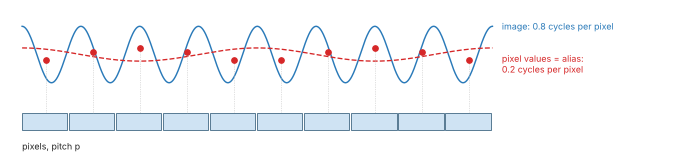

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.2))
sketch.pixel_sampling(ax)
plt.show()

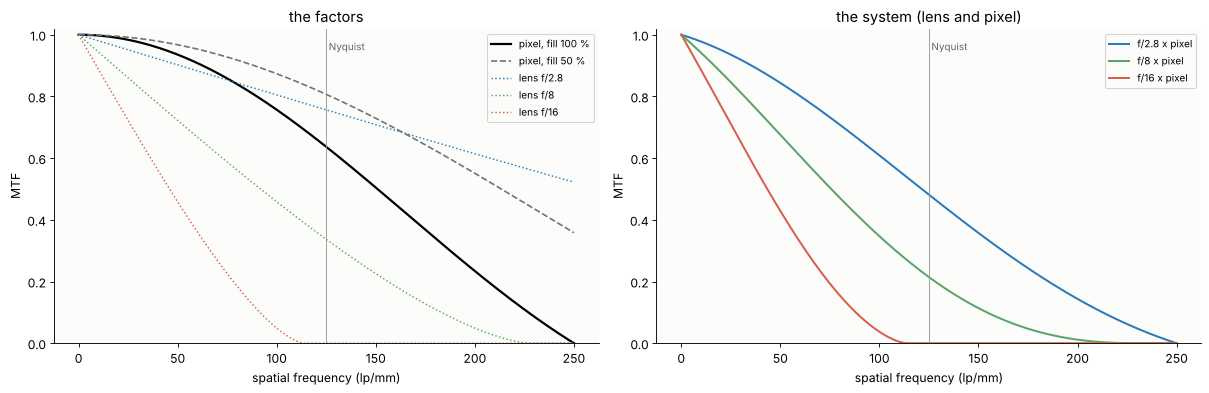

              MTF at Nyquist/2   at Nyquist   (62 and 125 lp/mm)
pixel           0.900          0.637
f/2.8  x pixel   0.790          0.482     (lens cut-off 649 lp/mm)
f/8    x pixel   0.589          0.214     (lens cut-off 227 lp/mm)
f/16   x pixel   0.303          0.000     (lens cut-off 114 lp/mm)


In [3]:
# MTF of the pixel aperture, of the lens (diffraction) and of both, for 4 um pixels
f = np.linspace(0, 2*F_NYQ, 400)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
ax[0].plot(f, se.pixel_mtf(f, P), color="k", lw=2, label="pixel, fill 100 %")
ax[0].plot(f, se.pixel_mtf(f, P, fill=0.5), color=GREY, lw=1.5, ls="--", label="pixel, fill 50 %")
cols = {2.8: BLUE, 8: GREEN, 16: RED}
for N, c in cols.items():
    ax[0].plot(f, se.diffraction_mtf(f, LAM, N), color=c, lw=1.3, ls=":", label="lens f/{:g}".format(N))
    ax[1].plot(f, se.diffraction_mtf(f, LAM, N)*se.pixel_mtf(f, P), color=c, lw=1.8,
               label="f/{:g} x pixel".format(N))
for a in ax:
    a.axvline(F_NYQ, color="0.6", lw=0.8)
    a.text(F_NYQ*1.01, 0.95, "Nyquist", color="0.4", fontsize=9)
    a.set_xlabel("spatial frequency (lp/mm)"); a.set_ylabel("MTF"); a.set_ylim(0, 1.02); a.legend(fontsize=9)
ax[0].set_title("the factors"); ax[1].set_title("the system (lens and pixel)")
plt.show()
print("              MTF at Nyquist/2   at Nyquist   ({:.0f} and {:.0f} lp/mm)".format(F_NYQ/2, F_NYQ))
print("pixel           {:.3f}          {:.3f}".format(se.pixel_mtf(F_NYQ/2, P), se.pixel_mtf(F_NYQ, P)))
for N in cols:
    m = lambda q: se.diffraction_mtf(q, LAM, N)*se.pixel_mtf(q, P)
    print("f/{:<4g} x pixel   {:.3f}          {:.3f}     (lens cut-off {:.0f} lp/mm)".format(
        N, m(F_NYQ/2), m(F_NYQ), 1/(LAM*N)))

Wide open the lens hardly matters and the pixel sets the MTF at Nyquist
(0.48 at f/2.8). By f/8 the diffraction MTF has fallen to a third at
Nyquist. At f/16 its cut-off $1/\lambda N = 114$ lp/mm lies below Nyquist,
so the lens itself removes everything that could alias. This is
the diffraction limit photographers notice when they stop down a high
resolution sensor.

The slanted edge method measures the MTF of a sampled system without a
special target. An edge tilted by a few degrees crosses the pixel columns
at a different phase in every row. Binning all pixels by their distance to
the fitted edge gives the edge spread function four times finer than the
pixels. Its derivative is the line spread function, whose Fourier transform
is the MTF (`se.slanted_edge_mtf()`). Here it is applied to simulated edges
(`se.slanted_edge()`, 128 × 128 pixels):

case          fitted angle   measured (theory) at 0.1, 0.25, 0.5, 0.75 cycles per pixel
pixel only     5.001 deg     0.984 (0.984)  0.902 (0.900)  0.641 (0.637)  0.305 (0.300)


f/8            4.994 deg     0.852 (0.846)  0.593 (0.589)  0.215 (0.214)  0.020 (0.026)


f/2.8          4.998 deg     0.938 (0.935)  0.793 (0.790)  0.484 (0.482)  0.190 (0.191)


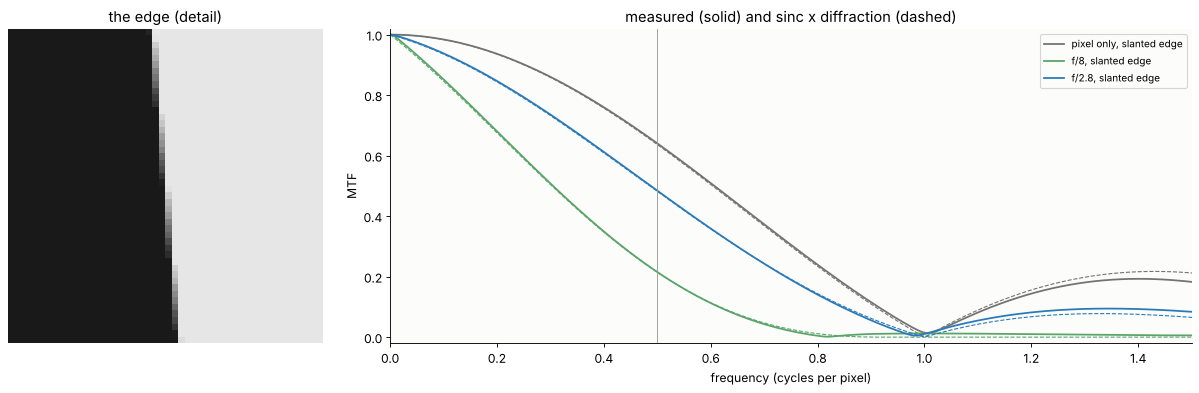

In [4]:
# the slanted edge method (ISO 12233) on simulated edges, against the product of the MTFs
angle = np.radians(5.0)
cases = [("pixel only", dict()), ("f/8", dict(wavelength=LAM, f_number=8)),
         ("f/2.8", dict(wavelength=LAM, f_number=2.8))]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1, 2.4]})
edge_img = None
print("case          fitted angle   measured (theory) at 0.1, 0.25, 0.5, 0.75 cycles per pixel")
for (name, kw), c in zip(cases, (GREY, GREEN, BLUE)):
    img = se.slanted_edge(128, angle, oversample=8, pitch=P, **kw)
    edge_img = img if edge_img is None else edge_img
    fq, m, ang = se.slanted_edge_mtf(img)
    theo = se.pixel_mtf(fq/P, P)*(se.diffraction_mtf(fq/P, LAM, kw["f_number"]) if kw else 1)
    ax[1].plot(fq, m, color=c, lw=1.6, label=name + ", slanted edge")
    ax[1].plot(fq, theo, color=c, lw=1.0, ls="--")
    q = np.array([0.1, 0.25, 0.5, 0.75])
    print("{:12s}  {:6.3f} deg     {}".format(name, np.degrees(ang), "  ".join(
        "{:.3f} ({:.3f})".format(np.interp(v, fq, m), np.interp(v, fq, theo)) for v in q)))
ax[0].imshow(edge_img[40:88, 40:88], cmap="gray", vmin=0, vmax=1)
ax[0].set_title("the edge (detail)"); ax[0].axis("off")
ax[1].axvline(0.5, color="0.6", lw=0.8)
ax[1].set_xlim(0, 1.5); ax[1].set_ylim(-0.02, 1.02)
ax[1].set_xlabel("frequency (cycles per pixel)"); ax[1].set_ylabel("MTF")
ax[1].set_title("measured (solid) and sinc x diffraction (dashed)"); ax[1].legend(fontsize=9)
plt.show()

The measured MTFs follow the products $\vert\mathrm{sinc}(f p)\vert \cdot
\mathrm{MTF}_{\rm lens}$ to within 0.01, also above Nyquist. At f/8 the
method reads 0.7 % high at low frequencies, because the long tails of the
diffraction line spread function are cut off by the 128 pixel window. A
256 pixel window halves that. The fitted edge angle is right to 0.01°.

The folding itself shows when a sine grating is imaged onto the pixels and
the pixel values are analysed:

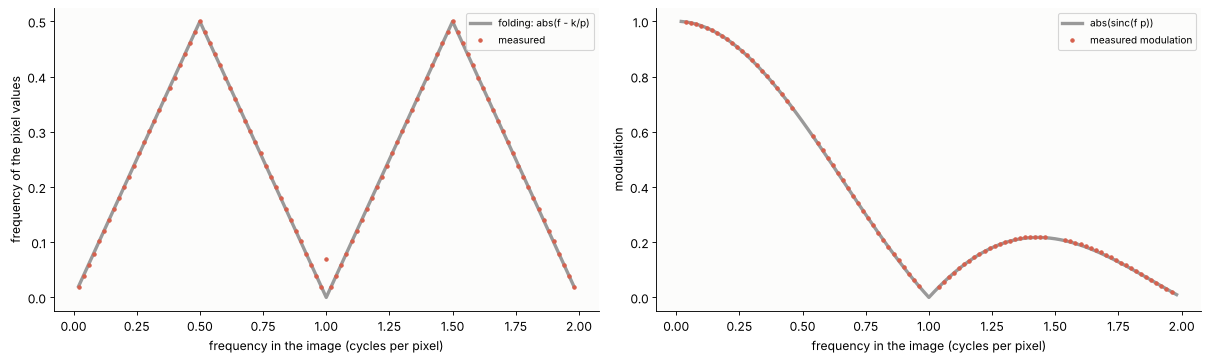

largest error of the folded frequency: 0.0019 cycles per pixel (one FFT bin: 0.0039)
largest error of the modulation against abs(sinc(f p)): 0.003


In [5]:
# a sine grating of frequency f_in imaged on the pixels: the frequency and amplitude the pixels report
os_, n = 16, 256
x = (np.arange(n*os_) + 0.5)/os_*P
f_in = np.linspace(0.02, 1.98, 99)/P
f_out, amp = [], []
for fi in f_in:
    row = se.sensor_image(np.tile(0.5*(1 + np.cos(2*np.pi*fi*x)), (os_, 1)), os_, P)[0]
    S = np.abs(np.fft.rfft((row - row.mean())*np.hanning(n)))
    k = np.argmax(S)
    f_out.append(np.fft.rfftfreq(n, P)[k])
    # modulation: least squares fit of a cosine and a sine at the folded frequency
    xs_ = (np.arange(n) + 0.5)*P
    fa = abs(fi - round(fi*P)/P)
    A = np.stack([np.cos(2*np.pi*fa*xs_), np.sin(2*np.pi*fa*xs_), np.ones(n)], axis=1)
    cs = np.linalg.lstsq(A, row, rcond=None)[0]
    amp.append(np.hypot(cs[0], cs[1])/0.5)
f_out, amp = np.array(f_out), np.array(amp)
f_fold = np.abs(f_in - np.round(f_in*P)/P)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
ax[0].plot(f_in*P, f_fold*P, color="0.6", lw=3, label="folding: abs(f - k/p)")
ax[0].plot(f_in*P, f_out*P, ".", color=RED, label="measured")
ax[0].set_xlabel("frequency in the image (cycles per pixel)"); ax[0].set_ylabel("frequency of the pixel values")
ax[0].legend(fontsize=9)
ax[1].plot(f_in*P, se.pixel_mtf(f_in, P), color="0.6", lw=3, label="abs(sinc(f p))")
half = np.abs(2*f_in*P - np.round(2*f_in*P)) > 0.05     # at multiples of Nyquist the phase of the samples decides
ax[1].plot(f_in[half]*P, amp[half], ".", color=RED, label="measured modulation")
ax[1].set_xlabel("frequency in the image (cycles per pixel)"); ax[1].set_ylabel("modulation")
ax[1].legend(fontsize=9)
plt.show()
ok = np.abs(f_in*P - np.round(f_in*P)) > 0.05
print("largest error of the folded frequency: {:.4f} cycles per pixel (one FFT bin: {:.4f})".format(
    np.max(np.abs(f_out - f_fold)[ok])*P, 1/n))
print("largest error of the modulation against abs(sinc(f p)): {:.3f}".format(
    np.max(np.abs(amp - se.pixel_mtf(f_in, P))[half])))

The pixels report the frequency $\vert f - k/p\vert$, folded at every
multiple of Nyquist, with the modulation $\vert\mathrm{sinc}(fp)\vert$ of
the original. A grating at 0.8 cycles per pixel looks exactly like one at
0.2, only weaker. After sampling nothing can tell them apart, so any
protection has to come before the sampling: from the lens, from the pixel
aperture, or from a low pass filter (section 3).

## 2. The Bayer mosaic and false colour

A Bayer sensor has one colour filter per pixel, in 2 × 2 cells of red,
green, green and blue. Red and blue are sampled at twice the pitch, and
green on a quincunx (checkerboard). Written in the Fourier domain, the raw
mosaic of a scene with colours $R, G, B$ is

$$\text{raw} = L + C_1\,(\cos\pi x/p + \cos\pi y/p)/2 + C_2\,\cos\pi x/p\,\cos\pi y/p ,$$

with the luminance $L = (R + 2G + B)/4$ in the baseband, the chrominance
$C_1 = (R - B)/2$ on the carriers $(1/2p, 0)$ and $(0, 1/2p)$, and
$C_2 = (R - 2G + B)/4$ on $(1/2p, 1/2p)$ (Alleysson et al.). A demosaicing
algorithm looks for colour near those carriers. If the scene itself has
luminance detail there, it cannot be told from colour, and grey detail is
decoded as false colour.

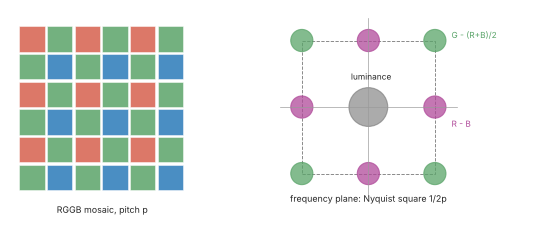

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
sketch.bayer_cfa(ax)
plt.show()

A zone plate, $\tfrac12(1 + \cos\pi r^2/r_0^2)$, is the ideal target
because its local frequency $r/r_0^2$ grows with the distance from the
centre. Every spatial frequency $(f_x, f_y)$ appears at its own place
$r_0^2(f_x, f_y)$ (`se.zone_plate_position()`). Here $r_0$ is chosen so that
the frequency reaches $1/p$ at the edge of a 256 pixel frame. The scene is
grey, so all colour in the result is false. The circles mark where the
carriers $(\pm 1/2p, 0)$, $(0, \pm 1/2p)$ and $(\pm 1/2p, \pm 1/2p)$ fall:

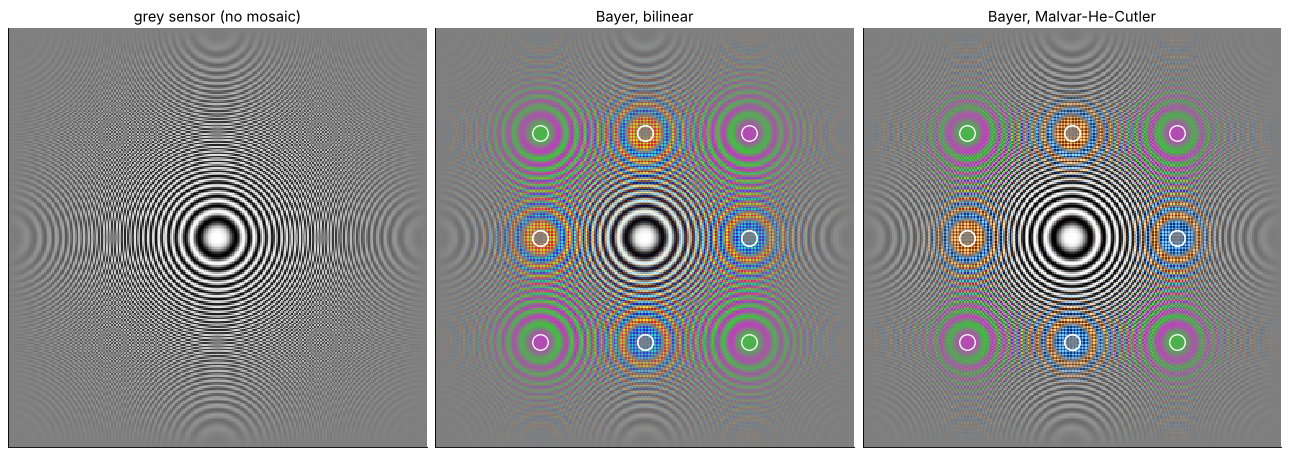

In [7]:
# a grey zone plate on a 256 x 256 pixel Bayer sensor: frequency 1/p at the edge of the frame
n, os_ = 256, 8
u = (np.arange(n*os_) + 0.5)/os_ - n/2                       # in pixels
U, V = np.meshgrid(u, u)
r0 = np.sqrt(n/2)                                            # local frequency r/r0**2: 1/p at r = n/2
scene = se.zone_plate(U, V, r0)
grey = se.sensor_image(scene, os_, 1.0)
raw = se.mosaic(np.array([grey]*3))
demo = {"bilinear": se.demosaic_bilinear(raw), "Malvar-He-Cutler": se.demosaic_malvar(raw)}

def show_rgb(a, rgb, title):
    a.imshow(np.clip(np.moveaxis(rgb, 0, -1), 0, 1), extent=[-n/2, n/2, n/2, -n/2], interpolation="nearest")
    a.set_title(title); a.set_xticks([]); a.set_yticks([])

fig, ax = plt.subplots(1, 3, figsize=(16, 5.6), layout="constrained")
ax[0].imshow(grey, cmap="gray", extent=[-n/2, n/2, n/2, -n/2], vmin=0, vmax=1, interpolation="nearest")
ax[0].set_title("grey sensor (no mosaic)"); ax[0].set_xticks([]); ax[0].set_yticks([])
for a, (name, rgb) in zip(ax[1:], demo.items()):
    show_rgb(a, rgb, "Bayer, " + name)
    for fx, fy in se.cfa_carriers(1.0):
        for sx in (1, -1):
            for sy in (1, -1):
                x0, y0 = se.zone_plate_position(sx*fx, sy*fy, r0)
                a.plot(x0, y0, "o", mfc="none", mec="w", ms=14, mew=1.2)
plt.show()

The grey sensor shows the aliasing of section 1: rings centred where the
zone plate reaches $1/p$ at the edges of the frame. The Bayer sensor adds
colour moiré centred exactly on the carriers. Bilinear interpolation and
the gradient corrected kernels of Malvar, He and Cutler (`se.demosaic_malvar()`,
the default of many raw converters) produce the same pattern, because no
linear demosaicing can tell detail from colour at a carrier. The colours
follow from the decomposition above:

In [8]:
# where the false colour is centred, and which colour difference it is
def lobe_centre(sig, xs):
    """Middle of the longest run of one sign: where the beat with the carrier is slowest."""
    s = np.sign(sig)
    e = np.flatnonzero(np.diff(s) != 0)
    k = np.argmax(np.diff(e))
    return 0.5*(xs[e[k] + 1] + xs[e[k + 1]])

c = n//2
xs = np.arange(n) + 0.5 - n/2
x_pred = se.zone_plate_position(0.5, 0.5, r0)[0]
print("predicted centre of the false colour: {:.1f} pixels from the middle, on the axes and the diagonal".format(x_pred))
for name, rgb in demo.items():
    rb = rgb[0] - rgb[2]
    gm = rgb[1] - 0.5*(rgb[0] + rgb[2])
    diag_rb = np.array([rb[c + k, c + k] for k in range(c)])
    diag_gm = np.array([gm[c + k, c + k] for k in range(c)])
    w = slice(int(x_pred) - 9, int(x_pred) + 9)
    print("{:17s} centre on x {:5.1f}, on y {:5.1f}, on the diagonal {:5.1f}".format(
        name, lobe_centre(rb[c, c:], xs[c:]), lobe_centre(rb[c:, c], xs[c:]),
        lobe_centre(diag_gm, xs[c:])*np.sqrt(1)))
    print("                  on the axis:     R-B {:.3f}   G-(R+B)/2 {:.3f}".format(
        np.abs(rb[c, c:][w]).mean(), np.abs(gm[c, c:][w]).mean()))
    print("                  on the diagonal: R-B {:.3f}   G-(R+B)/2 {:.3f}".format(
        np.abs(diag_rb[w]).mean(), np.abs(diag_gm[w]).mean()))

predicted centre of the false colour: 64.0 pixels from the middle, on the axes and the diagonal
bilinear          centre on x  64.0, on y  64.0, on the diagonal  64.0
                  on the axis:     R-B 0.324   G-(R+B)/2 0.082
                  on the diagonal: R-B 0.011   G-(R+B)/2 0.296
Malvar-He-Cutler  centre on x  64.0, on y  64.0, on the diagonal  64.0
                  on the axis:     R-B 0.319   G-(R+B)/2 0.005
                  on the diagonal: R-B 0.006   G-(R+B)/2 0.293


On the axes the false colour is $R - B$: orange and blue fringes. On the
diagonals it is $G - (R + B)/2$: green and magenta. The centres lie where the
theory puts them, 64 pixels out, to the pixel. The Malvar kernels keep the
two kinds cleanly apart, while bilinear demosaicing leaks a little
$G - (R+B)/2$ onto the axes.

How wide a band around each carrier turns into colour depends on how
smoothly the demosaicing interpolates the chrominance. The lens blur
limits how much detail reaches the carriers in the first place:

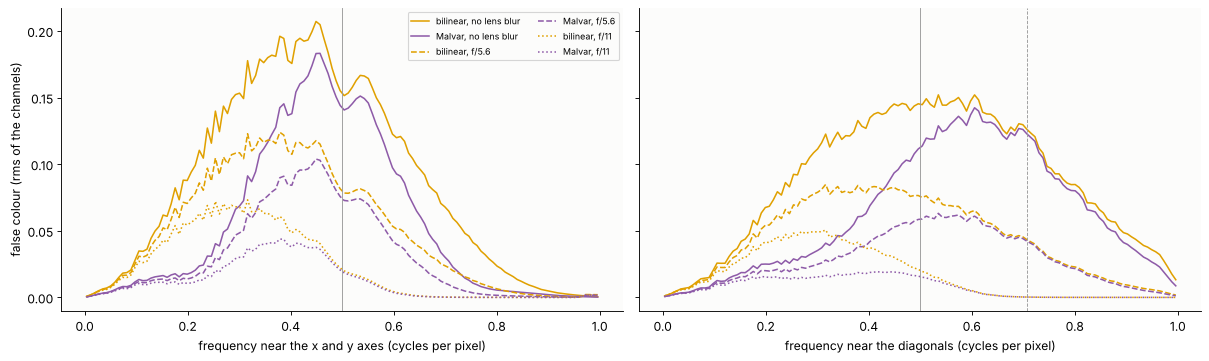

mean false colour over the frame (pixel pitch 4 um, 550 nm):
  no lens blur   bilinear 0.0665   Malvar 0.0463
  f/5.6          bilinear 0.0309   Malvar 0.0206
  f/11           bilinear 0.0097   Malvar 0.0052


In [9]:
# false colour against frequency along the x axis and along the diagonal, with and without lens blur
# averaged over sectors of +-10 deg around the x axes and around the diagonals, in rings 1 pixel wide
yy, xx = np.indices((n, n)) + 0.5 - n/2
rad, phi = np.hypot(xx, yy), np.degrees(np.arctan2(np.abs(yy), np.abs(xx)))
ring = np.minimum(rad.astype(int), c - 1)
def sector_mean(img, centre):
    sel = np.abs(phi - centre) < 10
    m = np.bincount(ring[sel], img[sel], c)/np.maximum(np.bincount(ring[sel], None, c), 1)
    return np.convolve(m, np.ones(7)/7, mode="same")             # smooth over 7 rings (the beat)
r = np.arange(c) + 0.5
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained", sharey=True)
fc_mean = {}
for N, ls in ((None, "-"), (5.6, "--"), (11, ":")):
    g = se.sensor_image(scene, os_, P, LAM, N) if N else grey
    for name, fn, col in (("bilinear", se.demosaic_bilinear, ORANGE), ("Malvar", se.demosaic_malvar, PURPLE)):
        fc = se.false_colour(fn(se.mosaic(np.array([g]*3))))
        fc_mean[(N, name)] = fc.mean()
        lab = "{}, {}".format(name, "f/{:g}".format(N) if N else "no lens blur")
        ax[0].plot(r/r0**2, sector_mean(fc, 0.0), color=col, ls=ls, lw=1.4, label=lab)
        ax[1].plot(r/r0**2, sector_mean(fc, 45.0), color=col, ls=ls, lw=1.4)
ax[0].set_xlabel("frequency near the x and y axes (cycles per pixel)")
ax[1].set_xlabel("frequency near the diagonals (cycles per pixel)")
ax[0].set_ylabel("false colour (rms of the channels)")
for a in ax:
    a.axvline(0.5, color="0.6", lw=0.8)
ax[1].axvline(np.sqrt(0.5), color="0.6", lw=0.8, ls="--")
ax[0].legend(fontsize=8, ncol=2)
plt.show()
print("mean false colour over the frame (pixel pitch 4 um, 550 nm):")
for N in (None, 5.6, 11):
    print("  {:14s} bilinear {:.4f}   Malvar {:.4f}".format("no lens blur" if N is None else "f/{:g}".format(N),
                                                         fc_mean[(N, "bilinear")], fc_mean[(N, "Malvar")]))

False colour appears in a band roughly ±0.25 cycles per pixel wide around
each carrier, the passband of the chrominance interpolation. The Malvar
kernels have about a third less of it than bilinear interpolation. Lens
blur helps more: at f/11 the diffraction MTF is low at the carriers and the
false colour falls to a tenth. Stopping down to f/11 to fight moiré works,
but it gives up sharpness everywhere. An optical low pass filter removes
just what aliases.

## 3. The birefringent optical low pass filter

In a uniaxial crystal such as quartz, light polarized in the plane of the
optic axis travels as the extraordinary wave. Its energy does not flow
along its wave vector. For a wave vector at the angle $\theta$ to the optic
axis, the Poynting vector makes the angle $\theta_S$ with
$\tan\theta_S = (n_o/n_e)^2\tan\theta$. A plate cut with its optic axis at
45° to the surface therefore shifts the extraordinary ray sideways by
$d = t\tan\rho$, $\rho = \theta - \theta_S$, while the ordinary ray goes
straight through. The formula is checked against the Poynting vector
$\mathbf S \propto \mathbf E\times(\mathbf k\times\mathbf E)$ of the
extraordinary eigenmode, computed from the dielectric tensor
(`se.poynting_direction()`):

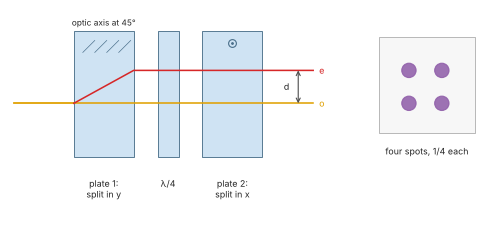

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.4))
sketch.olpf_plates(ax)
plt.show()

crystal          n_o     n_e     rho at 45 deg   max rho (at theta)        plate for d = 4 um
quartz           1.5462  1.5554    0.3399 deg      0.3399 deg (45.00 deg, atan(n_e/n_o) = 45.17)   0.674 mm   (tensor - formula: 1e-16 rad)
lithium niobate  2.3124  2.2238   -2.2362 deg      2.2379 deg (44.00 deg, atan(n_e/n_o) = 43.88)   0.102 mm   (tensor - formula: 8e-17 rad)


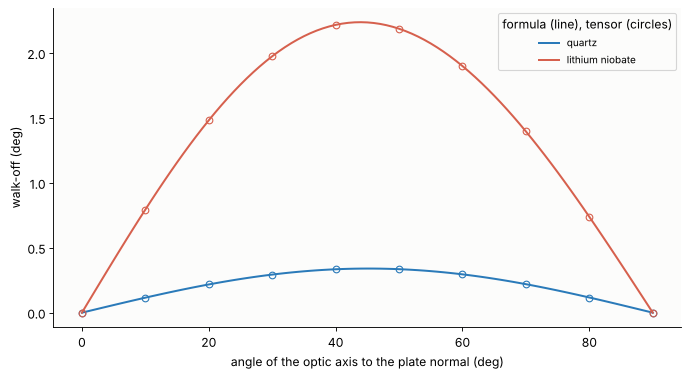

In [11]:
# walk-off of the extraordinary ray: closed form against the Poynting vector from the dielectric tensor
theta = np.radians(np.linspace(0, 90, 91))
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
print("crystal          n_o     n_e     rho at 45 deg   max rho (at theta)        plate for d = 4 um")
for name, (no, ne), col in (("quartz", se.QUARTZ, BLUE), ("lithium niobate", se.LITHIUM_NIOBATE, RED)):
    rho = se.walkoff_angle(no, ne, theta)
    ax.plot(np.degrees(theta), np.degrees(np.abs(rho)), color=col, lw=1.8, label=name)
    th_s = theta[::10]
    S = [se.poynting_direction(no, ne, [np.sin(t), 0, np.cos(t)], [0, 0, 1]) for t in th_s]
    rho_t = [np.arctan2(s[0], s[2]) for s in S]
    ax.plot(np.degrees(th_s), np.degrees(np.abs(rho_t)), "o", color=col, mfc="none")
    err = np.max(np.abs(np.array(rho_t) - se.walkoff_angle(no, ne, th_s)))
    k = np.argmax(np.abs(rho))
    print("{:15s}  {:.4f}  {:.4f}   {:7.4f} deg     {:7.4f} deg ({:.2f} deg, atan(n_e/n_o) = {:.2f})"
          "   {:.3f} mm   (tensor - formula: {:.0e} rad)".format(
              name, no, ne, np.degrees(se.walkoff_angle(no, ne)), np.degrees(abs(rho[k])), np.degrees(theta[k]),
              np.degrees(np.arctan(ne/no)), se.olpf_thickness(P, no, ne), err))
ax.set_xlabel("angle of the optic axis to the plate normal (deg)"); ax.set_ylabel("walk-off (deg)")
ax.legend(title="formula (line), tensor (circles)", fontsize=9)
plt.show()

The two agree to rounding. The walk-off is largest near
$\theta = \arctan(n_e/n_o)$, close to 45°. Quartz is weakly birefringent, so
a 0.67 mm plate is needed for a 4 µm split. Lithium niobate needs only
0.10 mm and is used in thin filters. In lithium niobate the walk-off has the
opposite sign (a negative crystal).

One plate makes a pair of spots, a low pass filter in one direction. A
second plate, turned by 90°, would only move the two orthogonally polarized
spots, each along its own polarization, and would still leave two. A
quarter wave plate in between makes both beams circularly polarized, so
that the second plate splits each of them again (`se.olpf_spots()`, a Jones
calculus of displaced copies):

two plates: (+1.00 p, +0.00 p): 0.500,  (+0.00 p, +1.00 p): 0.500
plate, quarter wave, plate: (+1.00 p, +1.00 p): 0.250,  (+1.00 p, +0.00 p): 0.250,  (+0.00 p, +1.00 p): 0.250,  (+0.00 p, +0.00 p): 0.250


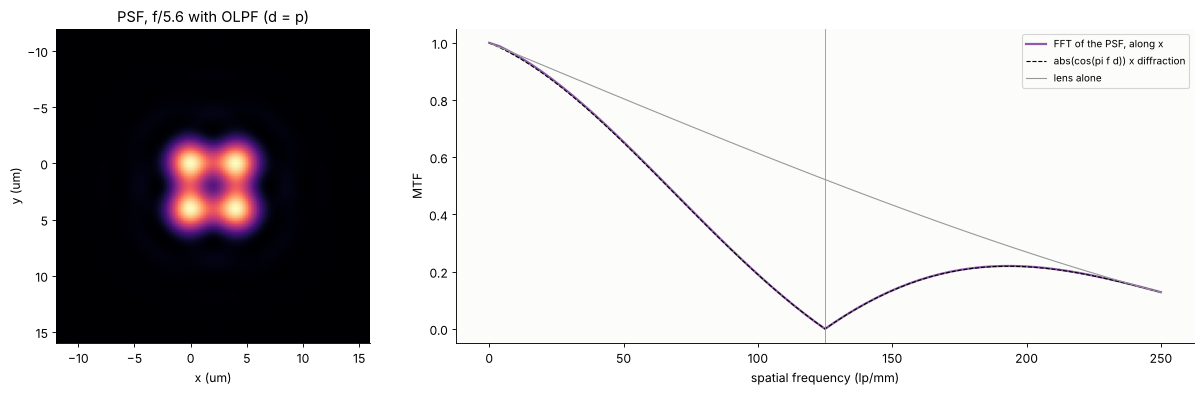

largest difference FFT - theory: 4.6e-03; zero of the filter at 1/(2d) = 125 lp/mm (Nyquist)


In [12]:
# the spots of two plates, without and with the quarter wave plate between them
t = se.olpf_thickness(P)
two = se.olpf_spots([se.OLPFPlate(t, 0.0), se.OLPFPlate(t, np.pi/2)])
four = se.olpf_spots([se.OLPFPlate(t, 0.0), se.WavePlate(np.pi/2, np.pi/4), se.OLPFPlate(t, np.pi/2)])
for name, sp in (("two plates", two), ("plate, quarter wave, plate", four)):
    print(name + ":", ",  ".join("({:+.2f} p, {:+.2f} p): {:.3f}".format(dx/P, dy/P, w) for dx, dy, w in sp))

# PSF at f/5.6: the Airy pattern at each spot, then its MTF by FFT, against cos x cos x diffraction
N = 5.6
L, m = 64*P, 1024
xg = (np.arange(m) - m//2)*L/m
X, Y = np.meshgrid(xg, xg)
def airy(r):
    v = np.pi*r/(LAM*N)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(v == 0, 1.0, (2*j1(v)/v)**2)
psf = sum(w*airy(np.hypot(X - dx, Y - dy)) for dx, dy, w in four)
otf = np.abs(np.fft.fft2(np.fft.ifftshift(psf)))
otf /= otf[0, 0]
fq = np.fft.fftfreq(m, L/m)
sel = (fq >= 0) & (fq <= 2*F_NYQ)
theory = np.abs(np.cos(np.pi*fq*P))*se.diffraction_mtf(fq, LAM, N)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1, 2]})
w = 3*P
ax[0].imshow(psf, extent=[xg[0]*1e3, xg[-1]*1e3, xg[-1]*1e3, xg[0]*1e3], cmap="magma")
ax[0].set_xlim(-w*1e3, (w + P)*1e3); ax[0].set_ylim((w + P)*1e3, -w*1e3)
ax[0].set_xlabel("x (um)"); ax[0].set_ylabel("y (um)"); ax[0].set_title("PSF, f/5.6 with OLPF (d = p)")
ax[1].plot(fq[sel], otf[0, sel], color=PURPLE, lw=2, label="FFT of the PSF, along x")
ax[1].plot(fq[sel], theory[sel], "--", color="k", lw=1, label="abs(cos(pi f d)) x diffraction")
ax[1].plot(fq[sel], se.diffraction_mtf(fq[sel], LAM, N), color="0.6", lw=1, label="lens alone")
ax[1].axvline(F_NYQ, color="0.6", lw=0.8)
ax[1].set_xlabel("spatial frequency (lp/mm)"); ax[1].set_ylabel("MTF"); ax[1].legend(fontsize=9)
plt.show()
print("largest difference FFT - theory: {:.1e}; zero of the filter at 1/(2d) = {:.0f} lp/mm (Nyquist)".format(
    np.max(np.abs(otf[0, sel] - theory[sel])), 1/(2*P)))

Without the wave plate there are two spots. With it there are four equal
spots on a square of side $d$. The point spread function becomes four
overlapping Airy patterns, and its MTF along $x$ is that of the lens times
$\vert\cos\pi f d\vert$, with the first zero at $1/2d$. With $d = p$ the zero
lies at the Nyquist frequency. The FFT of the PSF agrees with the product
to $5\times10^{-3}$.

A stronger filter removes more aliasing and costs more sharpness. Here are
the zone plate (Malvar demosaicing, f/5.6) and the MTF at half Nyquist from
the slanted edge for four filter strengths:

  d/p   plate (mm)   false colour (Malvar)   MTF at Nyquist/2: slanted edge   theory


  0.00   0.000        0.0206                  0.685                            0.681


  0.50   0.337        0.0138                  0.633                            0.629


  0.75   0.506        0.0080                  0.570                            0.566


  1.00   0.674        0.0048                  0.486                            0.482


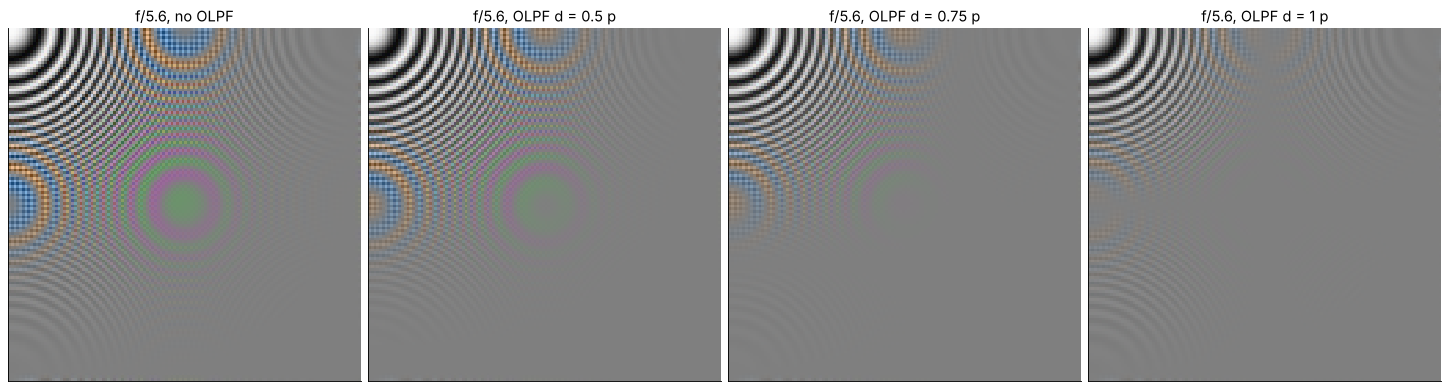

In [13]:
# filter strength d/p: false colour on the zone plate against the MTF (slanted edge) at Nyquist/2
lens_N = 5.6
print("  d/p   plate (mm)   false colour (Malvar)   MTF at Nyquist/2: slanted edge   theory")
imgs = {}
for dp in (0.0, 0.5, 0.75, 1.0):
    sp = None if dp == 0 else se.olpf_spots([se.OLPFPlate(se.olpf_thickness(dp*P), 0.0),
                                              se.WavePlate(np.pi/2, np.pi/4),
                                              se.OLPFPlate(se.olpf_thickness(dp*P), np.pi/2)])
    g = se.sensor_image(scene, os_, P, LAM, lens_N, spots=sp)
    rgb = se.demosaic_malvar(se.mosaic(np.array([g]*3)))
    imgs[dp] = rgb
    edge = se.slanted_edge(128, np.radians(5), oversample=8, pitch=P, wavelength=LAM, f_number=lens_N, spots=sp)
    fq, mm, _ = se.slanted_edge_mtf(edge)
    th = se.pixel_mtf(F_NYQ/2, P)*se.diffraction_mtf(F_NYQ/2, LAM, lens_N)*abs(np.cos(np.pi*F_NYQ/2*dp*P))
    print("  {:.2f}   {:.3f}        {:.4f}                  {:.3f}                            {:.3f}".format(
        dp, se.olpf_thickness(dp*P) if dp else 0.0, se.false_colour(rgb).mean(), np.interp(0.25, fq, mm), th))
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8), layout="constrained")
for a, (dp, rgb) in zip(ax, imgs.items()):
    show_rgb(a, rgb[:, c:, c:], "f/{:g}, OLPF d = {:g} p".format(lens_N, dp) if dp else "f/{:g}, no OLPF".format(lens_N))
plt.show()

With $d = p$ the false colour falls to a quarter of its value without a
filter, and the MTF at half Nyquist falls from 0.68 to 0.49. The slanted
edge measures the expected $\vert\cos(\pi f d)\vert$ to within 0.004. This
trade-off is why many high resolution cameras dropped the filter, or
offered models without it, once pixels became small enough that lens
diffraction and aberrations filter for them at most apertures.

## 4. Microlenses and the chief ray angle

The photodiode takes up only part of the pixel. The rest holds wiring in a
front side illuminated sensor and isolation in a back side illuminated
one. A microlens on every pixel collects the light that falls on the pixel
and focuses it onto the photodiode. Strictly, it images the exit pupil of
the camera lens onto the photodiode plane. The image is a disk of radius
$f\tan u$, where $f = R/(n-1)$ is the front focal length of the microlens
and $\sin u = 1/2N$. The disk is centred at $f\tan\theta$ for a chief ray
angle $\theta$ (`se.pupil_image()`). The paraxial efficiency is the fraction
of that disk on the photodiode (`se.disk_square_overlap()`).

The model pixel (`se.pixel_stack()`) is 4 µm wide. It has touching round
microlenses with $R = 2.8$ µm and $n = 1.55$, and a 2 × 2 µm photodiode in
the focal plane, 7.9 µm below. `se.trace_pixel()` traces rays from the
whole exit pupil cone through the microlens, or through the flat corners
between microlenses, to the photodiode plane:

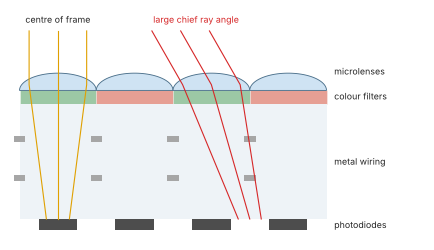

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sketch.microlens_pixels(ax)
plt.show()

microlens focal length in the stack 7.89 um; photodiode 2.0 um wide; microlens covers 78.5% of the pixel
 N      CRA    traced   paraxial   crosstalk
f/1.4     0    0.344    0.264      0.025


f/1.4    10    0.302    0.257      0.043
f/1.4    20    0.167    0.133      0.128


f/2.8     0    0.777    0.785      0.000
f/2.8    10    0.480    0.448      0.016


f/2.8    20    0.072    0.010      0.052
f/8       0    0.783    0.785      0.000


f/8      10    0.591    0.550      0.007
f/8      20    0.014    0.000      0.050


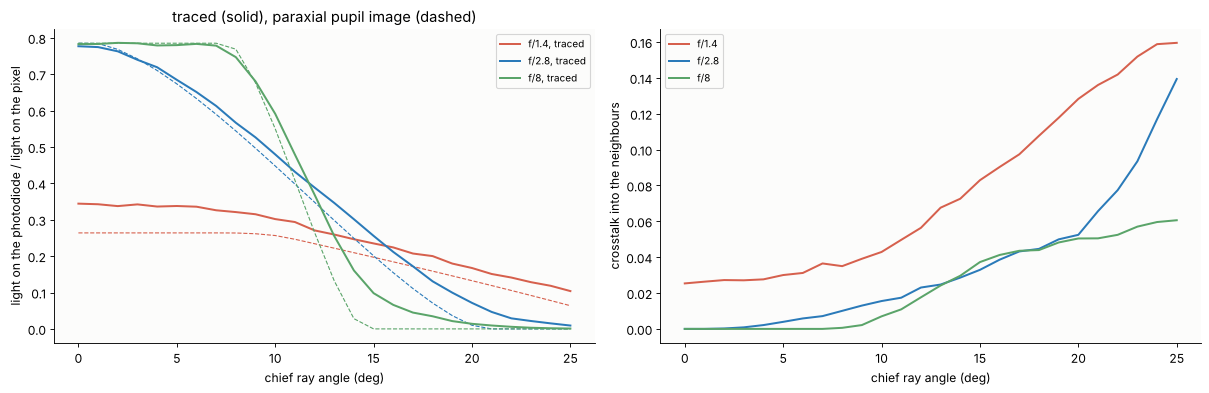

In [15]:
# a 4 um pixel: round microlens (a = 2 um, R = 2.8 um, n = 1.55), photodiode 2 x 2 um in its focal plane
st = se.pixel_stack(P)
print("microlens focal length in the stack {:.2f} um; photodiode {:.1f} um wide; microlens covers {:.1%} of the pixel".format(
    st.depth*1e3, 2*st.pd_half_width*1e3, np.pi*st.lens_radius**2/P**2))
cra = np.radians(np.arange(0, 26, 1.0))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
print(" N      CRA    traced   paraxial   crosstalk")
for N, col in ((1.4, RED), (2.8, BLUE), (8, GREEN)):
    eff, xt, par = [], [], []
    for a in cra:
        e, x_, _ = se.trace_pixel(st, a, N, 30000, rng)
        xc, rad = se.pupil_image(st, a, N)
        eff.append(e); xt.append(x_)
        par.append(np.pi*st.lens_radius**2/P**2*se.disk_square_overlap(xc, 0.0, rad, st.pd_half_width))
        if round(np.degrees(a)) in (0, 10, 20):
            print("f/{:<4g} {:4.0f}    {:.3f}    {:.3f}      {:.3f}".format(N, np.degrees(a), e, par[-1], x_))
    ax[0].plot(np.degrees(cra), eff, color=col, lw=1.8, label="f/{:g}, traced".format(N))
    ax[0].plot(np.degrees(cra), par, color=col, lw=1, ls="--")
    ax[1].plot(np.degrees(cra), xt, color=col, lw=1.8, label="f/{:g}".format(N))
ax[0].set_xlabel("chief ray angle (deg)"); ax[0].set_ylabel("light on the photodiode / light on the pixel")
ax[0].set_title("traced (solid), paraxial pupil image (dashed)"); ax[0].legend(fontsize=9)
ax[1].set_xlabel("chief ray angle (deg)"); ax[1].set_ylabel("crosstalk into the neighbours"); ax[1].legend(fontsize=9)
plt.show()

On the axis at f/2.8 and slower, 78 % of the light reaches the
photodiode, the area the round microlens covers. The rest falls on the flat
corners and is lost. As the chief ray angle grows, the pupil image walks
off the photodiode: at f/8 the pixel holds its efficiency up to about 7°
and loses almost everything by 15°. A wide cone (small $N$) makes a larger
pupil image. That image is lost even on the axis, but it fades more slowly
with angle. The paraxial disk follows the traced curves, which run a little
further because of the aberrations of the strongly curved microlens. Above
about 10°, part of the light lands in the neighbouring photodiode. That
pixel has a different colour filter, so this crosstalk desaturates colours
and tints them.

The loss at large apertures also shows on the axis:

In [16]:
# on the axis: the light the pixel loses at large apertures, in stops relative to f/8
Ns = np.array([1.2, 1.4, 2.0, 2.8, 4, 5.6, 8, 11, 16])
e_ax = np.array([se.trace_pixel(st, 0.0, N, 60000, rng)[0] for N in Ns])
loss = np.log2(e_ax/e_ax[Ns == 8][0])
for N, e, l in zip(Ns, e_ax, loss):
    print("f/{:<4g} efficiency {:.3f}   {:+.2f} stops".format(N, e, l))

f/1.2  efficiency 0.257   -1.60 stops
f/1.4  efficiency 0.342   -1.19 stops
f/2    efficiency 0.619   -0.33 stops
f/2.8  efficiency 0.778   -0.01 stops
f/4    efficiency 0.782   +0.00 stops
f/5.6  efficiency 0.785   +0.01 stops
f/8    efficiency 0.780   +0.00 stops
f/11   efficiency 0.785   +0.01 stops
f/16   efficiency 0.784   +0.01 stops


With this pixel the light gained by opening the lens beyond f/2.8 is
partly lost again: about a third of a stop at f/2 and more than a stop at
f/1.4. The microlens cannot fit a wider cone onto the photodiode. Measured
camera sensors show the same effect in milder form (larger photodiodes in
back side illuminated sensors). Cameras that compensate for it raise the
gain at large apertures, so that f/1.4 delivers the exposure it promises
on paper.

The chief ray angle grows with the image height $r$ as $\arctan(r/z)$,
where $z$ is the distance of the exit pupil from the sensor. Shifting each
microlens towards the centre of the frame by the amount the chief ray
walks (`se.microlens_shift()`) recovers the light, but only for one value
of $z$. Here a full frame sensor has its microlenses shifted for an exit
pupil 80 mm away, typical of lenses designed for single lens reflex
cameras. A lens with a pupil 25 mm away has steep chief rays at the corner
(41°), as many short rangefinder wide angle lenses do:

lens pupil   microlenses     efficiency at r = 0, 10.8, 21.6 mm     crosstalk at the corner
   80 mm     not shifted     0.781  0.646  0.194                          0.032


   80 mm     shifted         0.783  0.782  0.761                          0.000
   25 mm     not shifted     0.783  0.009  0.000                          0.506


   25 mm     shifted         0.785  0.191  0.031                          0.217


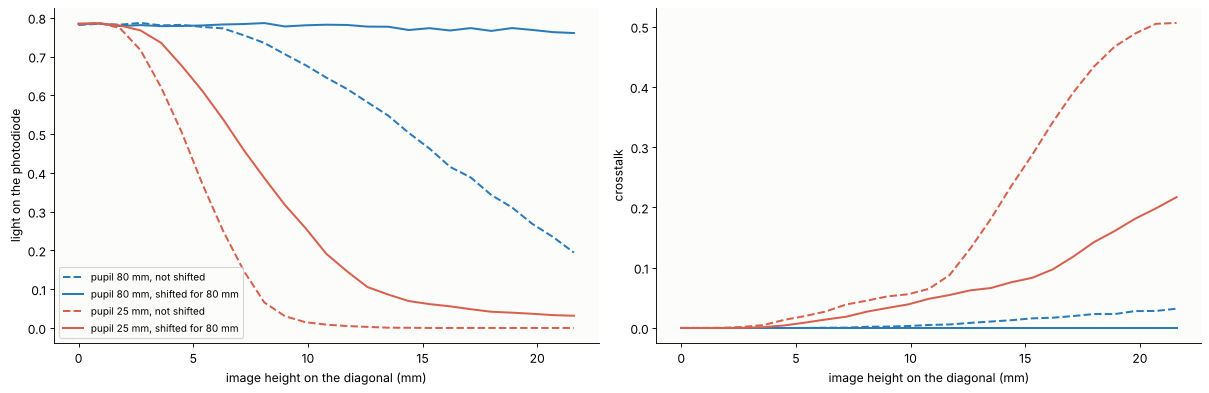

In [17]:
# along the diagonal of a full frame sensor (21.6 mm): two lenses at f/4 with exit pupils 80 mm and
# 25 mm in front of the sensor; microlenses shifted for the 80 mm pupil, or not shifted
r_img = np.linspace(0, 21.6, 25)
z_design = 80.0
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
print("lens pupil   microlenses     efficiency at r = 0, 10.8, 21.6 mm     crosstalk at the corner")
for z_xp, col in ((80.0, BLUE), (25.0, RED)):
    for shifted, ls in ((False, "--"), (True, "-")):
        eff, xt = [], []
        for r in r_img:
            a = np.arctan(r/z_xp)
            s = se.microlens_shift(st, np.arctan(r/z_design)) if shifted else 0.0
            e, x_, _ = se.trace_pixel(st._replace(shift=s), a, 4.0, 20000, rng)
            eff.append(e); xt.append(x_)
        lab = "pupil {:g} mm, {}".format(z_xp, "shifted for 80 mm" if shifted else "not shifted")
        ax[0].plot(r_img, eff, color=col, ls=ls, lw=1.8, label=lab)
        ax[1].plot(r_img, xt, color=col, ls=ls, lw=1.8, label=lab)
        print("{:5.0f} mm     {:12s}    {:.3f}  {:.3f}  {:.3f}                          {:.3f}".format(
            z_xp, "shifted" if shifted else "not shifted", eff[0], eff[12], eff[-1], xt[-1]))
ax[0].set_xlabel("image height on the diagonal (mm)"); ax[0].set_ylabel("light on the photodiode")
ax[1].set_xlabel("image height on the diagonal (mm)"); ax[1].set_ylabel("crosstalk")
ax[0].legend(fontsize=9)
plt.show()

With the pupil it was designed for, the shifted sensor holds its
efficiency to the corner (0.76 against 0.78 at the centre). Without the
shift it would keep only 0.19. The lens with the near pupil loses most of
its light by mid-frame even on the shifted sensor, and at the corner a
fifth of the light goes to the neighbours. Such lenses show this on
digital bodies as dark corners with colour casts and smeared detail. It is
also why lenses made for digital sensors keep their exit pupils far from
the sensor (image space telecentricity).

This model is purely geometric. The microlens is only a few wavelengths
wide, and the diffraction spot at its focus (radius about $0.6\lambda/{\rm NA}
\approx 0.9$ µm) is comparable to the photodiode. A wave optical model (an FDTD
simulation of the pixel stack, as in notebooks 57 to 65) softens the edges of these curves
but keeps their positions.

## Summary

- A pixel without gaps has the MTF $\vert\mathrm{sinc}(fp)\vert$: 0.90 at half
  Nyquist and 0.64 at Nyquist. Frequencies above Nyquist fold back as
  $\vert f - k/p\vert$ with that modulation. The slanted edge method
  measures the sampled MTF to within 0.01 of the product of pixel and lens
  MTFs.
- The Bayer mosaic carries $R - B$ on the axis carriers $(1/2p, 0)$ and
  $G - (R+B)/2$ on the diagonal carrier $(1/2p, 1/2p)$. On a zone plate, false
  colour appears centred exactly at $r_0^2/2p$: orange and blue on the
  axes, green and magenta on the diagonals. Malvar demosaicing reduces it
  by a third, and stopping down to f/11 by a factor of ten.
- A birefringent plate shifts the extraordinary ray by $t\tan\rho$, with
  $\tan(\theta - \rho) = (n_o/n_e)^2\tan\theta$, as the dielectric tensor
  confirms to rounding. Two plates with a quarter wave plate between them
  give four spots and the MTF $\vert\cos\pi f_xd\,\cos\pi f_yd\vert$. With
  $d = p$ it cuts the false colour to a quarter and the MTF at half Nyquist
  from 0.68 to 0.49.
- A microlens images the exit pupil onto the photodiode. Fast apertures
  overfill it (more than a stop lost at f/1.4 for this pixel), and chief
  ray angles beyond about 10° walk the image off it and into the
  neighbours. Shifting the microlenses for an exit pupil distance restores
  the corners for lenses with that pupil distance, but not for lenses with
  a much closer one.

In [18]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 13 s


## References

- G. C. Holst and T. S. Lomheim, *CMOS/CCD Sensors and Camera Systems*, 2nd
  ed., SPIE Press (2011), chapters 10 and 11.
- ISO 12233:2017, *Photography: Electronic still picture imaging,
  Resolution and spatial frequency responses*.
- P. D. Burns, "Slanted-edge MTF for digital camera and scanner analysis",
  Proc. IS&T PICS Conference, 135–138 (2000).
- B. E. Bayer, "Color imaging array", US patent 3,971,065 (1976).
- D. Alleysson, S. Süsstrunk and J. Hérault, "Linear demosaicing inspired
  by the human visual system", IEEE Trans. Image Process. 14, 439–449
  (2005).
- H. S. Malvar, L.-W. He and R. Cutler, "High-quality linear interpolation
  for demosaicing of Bayer-patterned color images", Proc. IEEE ICASSP 3,
  485–488 (2004).
- J. E. Greivenkamp, "Color dependent optical prefilter for the suppression
  of aliasing artifacts", Appl. Opt. 29, 676–684 (1990).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University
  Press (1999), section 15.3.
- P. B. Catrysse and B. A. Wandell, "Optical efficiency of image sensor
  pixels", J. Opt. Soc. Am. A 19, 1610–1620 (2002).